# **Ant Project Notebook**
***
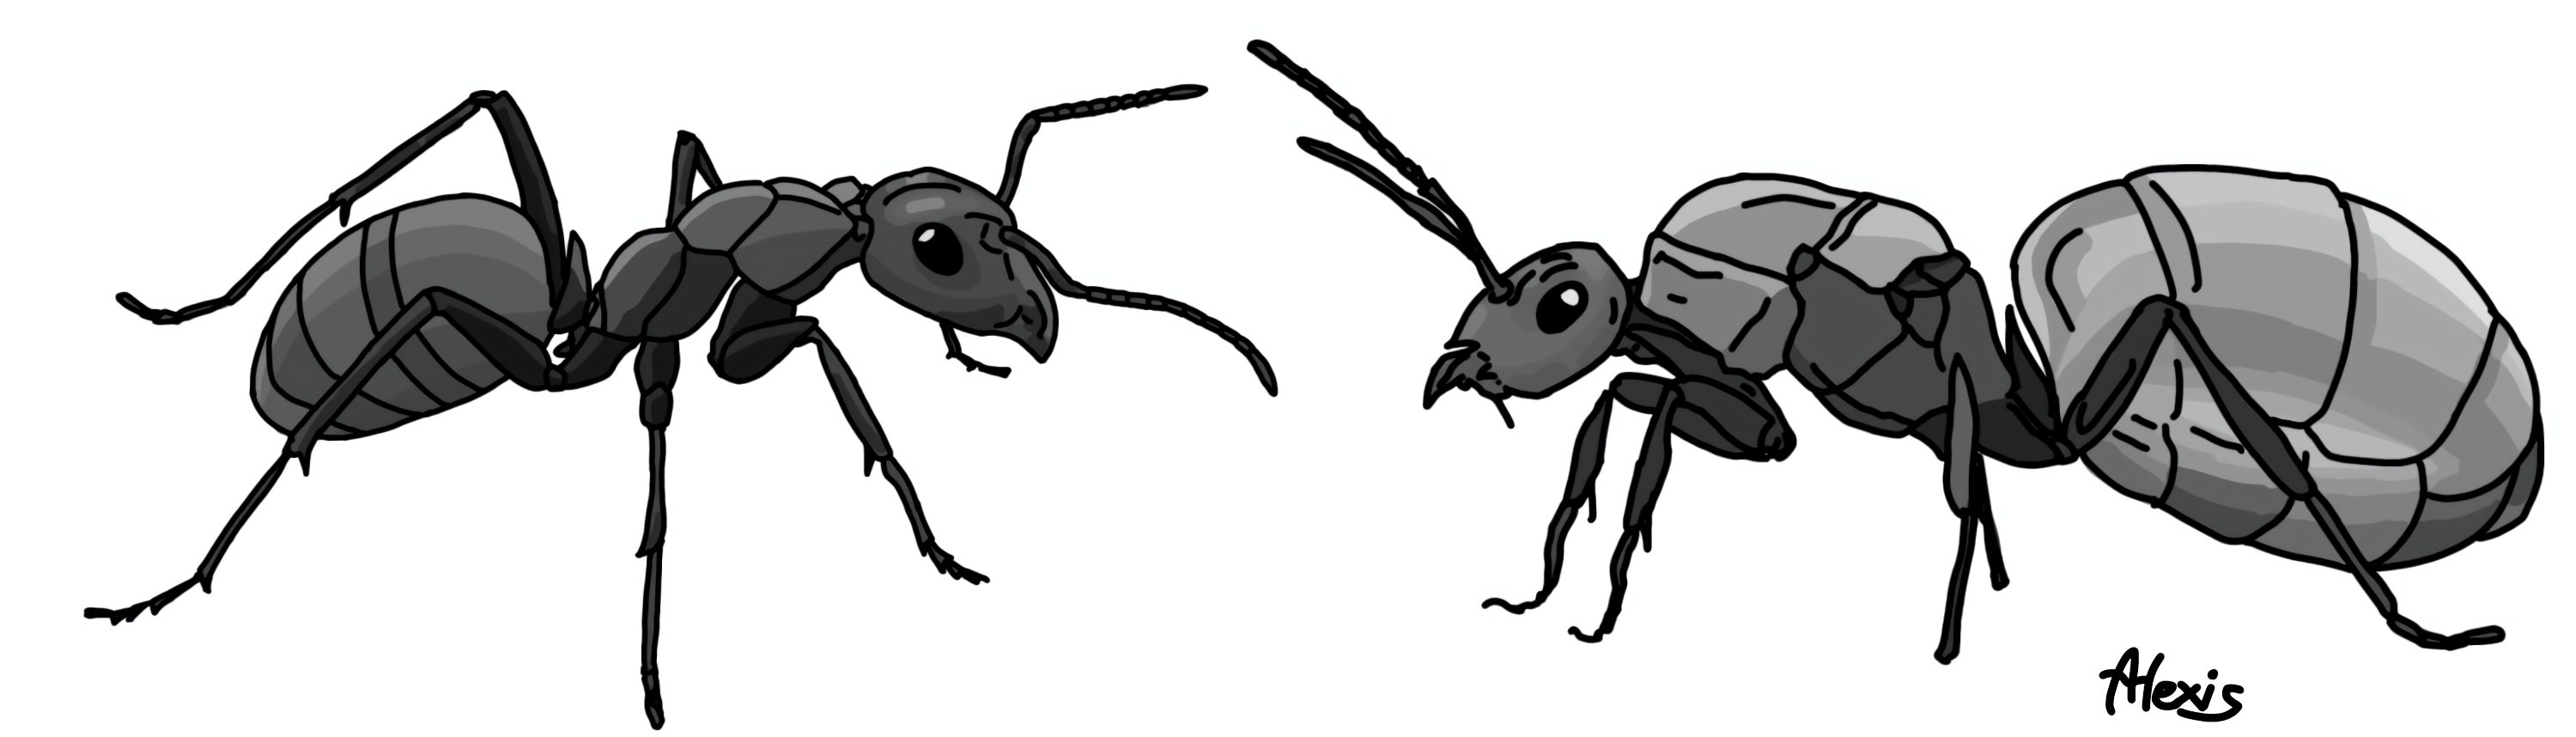
***

### **Import Useful Libraries**
Just, below we imported all the useful libraries and custom script `ant_dataset_generator.py`:

In [2]:
### --- Libraries for General Use --- ###
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

### --- Libraries for Adaptative Data Loading ---
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

### --- Loading Script for Data Generation --- ###
if IN_COLAB and not os.path.exists('ant_dataset_generator.py'):
    !wget https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/ant_dataset_generator.py
# This custom script generates data based on random sampling of each features within their biological range.

### --- Libraries for Data Transformation --- ###
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

### --- Libraries for Models' Hyperparameters Tuning --- ###
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV

### --- Libraries for Logistic Regression --- ###
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve, 
    confusion_matrix)

### --- Libraries for Decision Tree --- ###
from sklearn.tree import DecisionTreeClassifier

### --- Libraries for Random Forest --- ###
from sklearn.ensemble import RandomForestClassifier

### --- Libraries for XGBoost --- ###
from xgboost import XGBClassifier

### --- Libraries for Neural Networks --- ###
from sklearn.neural_network import MLPClassifier

### **Creating Helper Plotting Functions for the Subsequent Parts**

*In the cell below, we created two helper functions called `plot_feature_distr` and `plot_feature_pairwise_corr`.*

1. **`barplot_polymorphic_or_not`:** This helper function plots a barplot displaying the polymorphic fraction against the non polymorphic fraction.
2. **`plot_feature_distr`:** This helper function helps to plot the non polymorphic and polymorphic distribution separately for each features and make a grouped figure.
3. **`plot_feature_pairwise_corr`:** This helper function helps to plot the corroleation matrix of all the features and response variable.
4. **`plot_confusion_matrix`:** This helper function, given a model and data set (training, validation or test), helps display the confusion matrix of the model.
5. **`plot_roc`:** This helper function, given a model and data set (training, validation or test), plots the ROC and AUC

In [3]:
### --- Polymorphic Versus Non Polymorphic Barplot Helper --- ###
def barplot_polymorphic_or_not(df, polymorph_treshold=0.0):
       # Note on polymorph_treshold=0.0:
       # This treshold is the minimum percentage of cases 
       # required for us to consider that there is some 
       # polymorphism. Here anything that displayed at 
       # least a replicate with the allele maintained was 
       # considered maintaing polymorphism. Feel free to play
       # with it a bit.

       # Identify all the polymorphic cases
       polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold)

       # Create the barplot of the non-polymorphic vs polymorphic fraction.
       fig, ax = plt.subplots() # Creates the barplot.
       ax.bar([0, 1], [1-polymorph_samples.mean().item(), polymorph_samples.mean().item()], 
              color='skyblue') # Display the two bars.
       ax.set_xticks(ticks=[0, 1], labels=['Non Polymorphic', 'Polymorphic']) # Set axis x.
       ax.set_ylabel('Fraction of Samples') # Set axis y and below title.
       ax.set_title('Non-Polymorphic vs Polymorphic Fraction', fontweight='bold', pad=15)
       # Display plot.
       plt.show()

### --- Features Distribution Plotting Helper Function --- ###
def plot_feature_distr(df, params, polymorph_treshold=0.0):
  polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold) # Separating the non polymorphic versus 
                                                                    # polymorphic sample.
  fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(15, 12)) # Figure shape and size.
  for i, col_name in enumerate(params): # Iterating for each parameters and plotting its distribution.
      ax = axs[i // 4, i % 4]
      # Plotting the non polymorphic and polymorphic distribution separately on the same plot.
      ax.hist(df[polymorph_samples][col_name], bins=20, alpha=0.5, label='Polymorphic', density=True)
      ax.hist(df[~polymorph_samples][col_name], bins=20, alpha=0.5, label='Non Polymorphic', density=True)
      ax.set_title(col_name, fontweight='bold')
      ax.set_xlabel('Value') 
      ax.set_ylabel('Frequency')
  handles, labels = ax.get_legend_handles_labels()
  # Adding the rest of the legend.
  fig.legend(handles, labels, bbox_to_anchor=[0.97, 0.2], fontsize=18)
  fig.delaxes(axs[-1][-1])
  plt.tight_layout()
  plt.show()

### --- Plotting Correlation Table Helper Function --- ###
def plot_feature_pairwise_corr(df):
  corr_matrix = df.corr() # Obtain the correlation table.
  # Plot and display the correlation table.
  fig, ax = plt.subplots(figsize=(10, 8))
  cax = ax.matshow(corr_matrix, cmap='PuOr', vmin=-1, vmax=1)
  ax.set_xticks(range(len(corr_matrix.columns)))
  ax.set_yticks(range(len(corr_matrix.columns)))
  ax.set_xticklabels(corr_matrix.columns, rotation=90)
  ax.set_yticklabels(corr_matrix.columns)
  fig.colorbar(cax)

### --- Plotting the Confusion Matrix Helper Function --- ###
def plot_confusion_matrix(model, X_set, y_set, type_of_set="Test"):
    # Plots a custom confusion matrix with TN, FP, FN, TP labels and PuOr colormap.
    cm = confusion_matrix(y_set, model.predict(X_set)) 
    TN, FP, FN, TP = cm.ravel()

    # Add the annotations
    annot_labels = np.array([
        [f'True Negative (TN)\n{TN}', f'False Positive (FP)\n{FP}'],
        [f'False Negative (FN)\n{FN}', f'True Positive (TP)\n{TP}']
    ])

    # Plotting the confusion matrix, with labels and title
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=annot_labels, fmt='', cmap='PuOr', cbar=True, 
                linewidths=2, annot_kws={'size': 12, 'weight': 'bold'})
    plt.title(f'Confusion Matrix of the {type_of_set} Set', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.show()

### --- Plotting the ROC Helper Function --- ###
def plot_roc(model, X_set, y_set, type_of_set="Test"):
    # Plots the ROC curve with sky-blue AUC fill and orange curve line.
    # Calculate the false positive rate and the true positive rate.
    y_test_proba = model.predict_proba(X_set)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_set, y_test_proba)
    auc_score = roc_auc_score(y_set, y_test_proba)

    # Plot the figure.
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='orange', lw=2, label='ROC Curve')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.fill_between(fpr, tpr, color='skyblue', alpha=0.4, label=f'AUC (={auc_score:.3f})')

    # Add the legend, label and title.
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Receiver Operating Characteristic (ROC) for the {type_of_set} Set', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

## **Data Generation Procedure**

*In this section, we explain how we generated the `.csv` data. For each feature we randomly generated a value within its biological range. Thus, each row in the generated `.csv` file represents a combination of all the randomly generated features (parameters' set) and the targets (what happened to the de novo rare allele over `reps` replicate simulations).*

<div class='alert alert-block alert-info'>
<b>Model in one paragraph:</b> A structured metapopulation of Nd (fixed to 100) ant colonies with Nq (1 to 10) queens each; de novo allele (freshly appeared in the population) starts in ic (fixed to 20) colonies. The queen and the workers have their own optimum, respectively 1 and 0. The parameter z represents the actual fitness (0 to 1), or how close we are to the worker and queen optimum. Additionally, we have the allele effect s (-0.1 to 0.1, same for both) and dominance d; performance is 1 - (trait - z)^2. Finally, we track the allelic change of the de novo allele over T (fixed to 10'000) generation.
</div>

The other parameters used in the ants life cycle simulation are:

1. **Nm:** *number of reproductive males, ranges from 1 to 20.*
2. **s:** *survival rate, each ranges from 0.0 to 1.0.*
3. **e:** *extinction rate, each ranges from 0.0 to 1.0.*
4. **m:** *migration rate, each ranges from 0.0 to 1.0.*
5. **dq:** *dominance in the queens, each ranges from 0.0 to 1.0.*
6. **dw:** *dominance in the workers, each ranges from 0.0 to 1.0.*

For every tested value, we stored the following:
1. **all the features value used**
2. **n_reps:** *corresponds to the number of replicate for each features' set and was kept the same during the whole data generation (here it was fixed to a 100).*
3. **mean_pA:** *it is the mean allelic frequency, resulting from the arithmetic mean of each replicates' allelic frequency.*
4. **sd_pA:** *it is the standard deviation of the mean allelic frequency.*
5. **frac_lost:** *percentage of the replicates where the rare de novo allele was lost.*
6. **frac_fixed:** *percentage of the replicates where the rare de novo allele was fixed.*
7. **frac_polymorphic:** *percentage of the replicates where the rare de novo allele was neither fixed nor lost.*

<div class='alert alert-block alert-info'>
<b>Setup:</b> Keep ant_dataset_generator.py and ant_ml_dataset.csv in the same folder as this notebook if you are working locally. If you are working on collab it does not matter.
</div>

### **Figure 1: Life Cycle Simulation Schematics**
***
![Sans titre.jpg](<attachment:Sans titre.jpg>)
***

#### **Figure 1 Explanation:**
*Here is the full ant life cycle we modeled, happening for Nd deems (ant colonies), it’s the ecological backbone of the simulation. Let's go trough it quickly: colonies can either survive or go extinct. Then, surviving colonies first produce workers, and later sexuals. Once, the sexual are produced they need to mate, which can either happen locally or during a mating flights and occurs with Nm mating males.*

- *Survival correspond to the probability of queen that just reproduced to survive another cycle.*
- *Dispersal correspond to the probability of a local queen or another queen issued from dispersal to recolonize an empty queen slot.*

*Eventually, recolonization occurs and fill all the queen’s slots left empty from the queen’s death due to survival or deme extinction. With this ecological foundation in place, we can now connect genotype to phenotype and see how alleles actually affect queens and workers.*

### **Figure 2: Queen and Workers Phenotype/Genotypes:**
***
![Capture d’écran 2026-10-30 à 18.40.58.png](<attachment:Capture d’écran 2026-10-30 à 18.40.58.png>)
***

#### **Figure 2 Explanation:**
*In the model, we consider one focal diploid locus with two alleles, A (being the de novo allele) and a. These alleles have opposite effects in queens and workers, which then feed into colony fecundity and ultimately allele transmission.*

## **Data Loading**
Here, we loaded the data we previously generated, using the `ant_dataset_generator.py` script. Additionally, we removed some of the uninformative variables already (a bit of cleaning), among them:
1. **`frac_lost` and `frac_fixed`:** We removed them, as they are redundant with `frac_polymorphic`. Since, they are related by the following formula: <br> $1 -($`frac_lost`$+$`frac_fixed`$)=$`frac_polymorphic`
2. **`n_reps`:** It corresponds to the number of replicate for each features set and was kept identical during the whole data generation (here it was fixed to a 100). So, it does not vary.
3. **`mean_pA`:** The mean allelic frequency is a tricky response variable. What would one would expect when they see a mean allelic frequency of 0.5 is a high prevalence of polymorphism in most replicates. Whereas, what often happen is we have a high prevalence of fixed allele due to its positive effect on the fitness (`mean_pA`$=1$) and a high loss of the allele (`mean_pA`$=0$), simply due to stochastics. Thus without any polymorphism being maintained, we are observing an average `mean_pA` simply thanks to loss and fixation of the allele.
4. **`sd_pA`:** is simply the standard deviation of the mean allelic frequency after 10'000 generations. As we just explained, we saw that the mean allelic frequency is not a good metric. Thus, `sd_pA` is not a useful either.

<div class='alert alert-block alert-info'>
<b>[Optionnal]:</b> The commented code part in the cell below helps you generate the data again if you wish (account for about 5 days of runtime if run locally and 2 on collab). Else, you can use the ant_ml_dataset.csv instead, by putting it in the same folder if working locally (else if you are collab it does not matter).
</div>
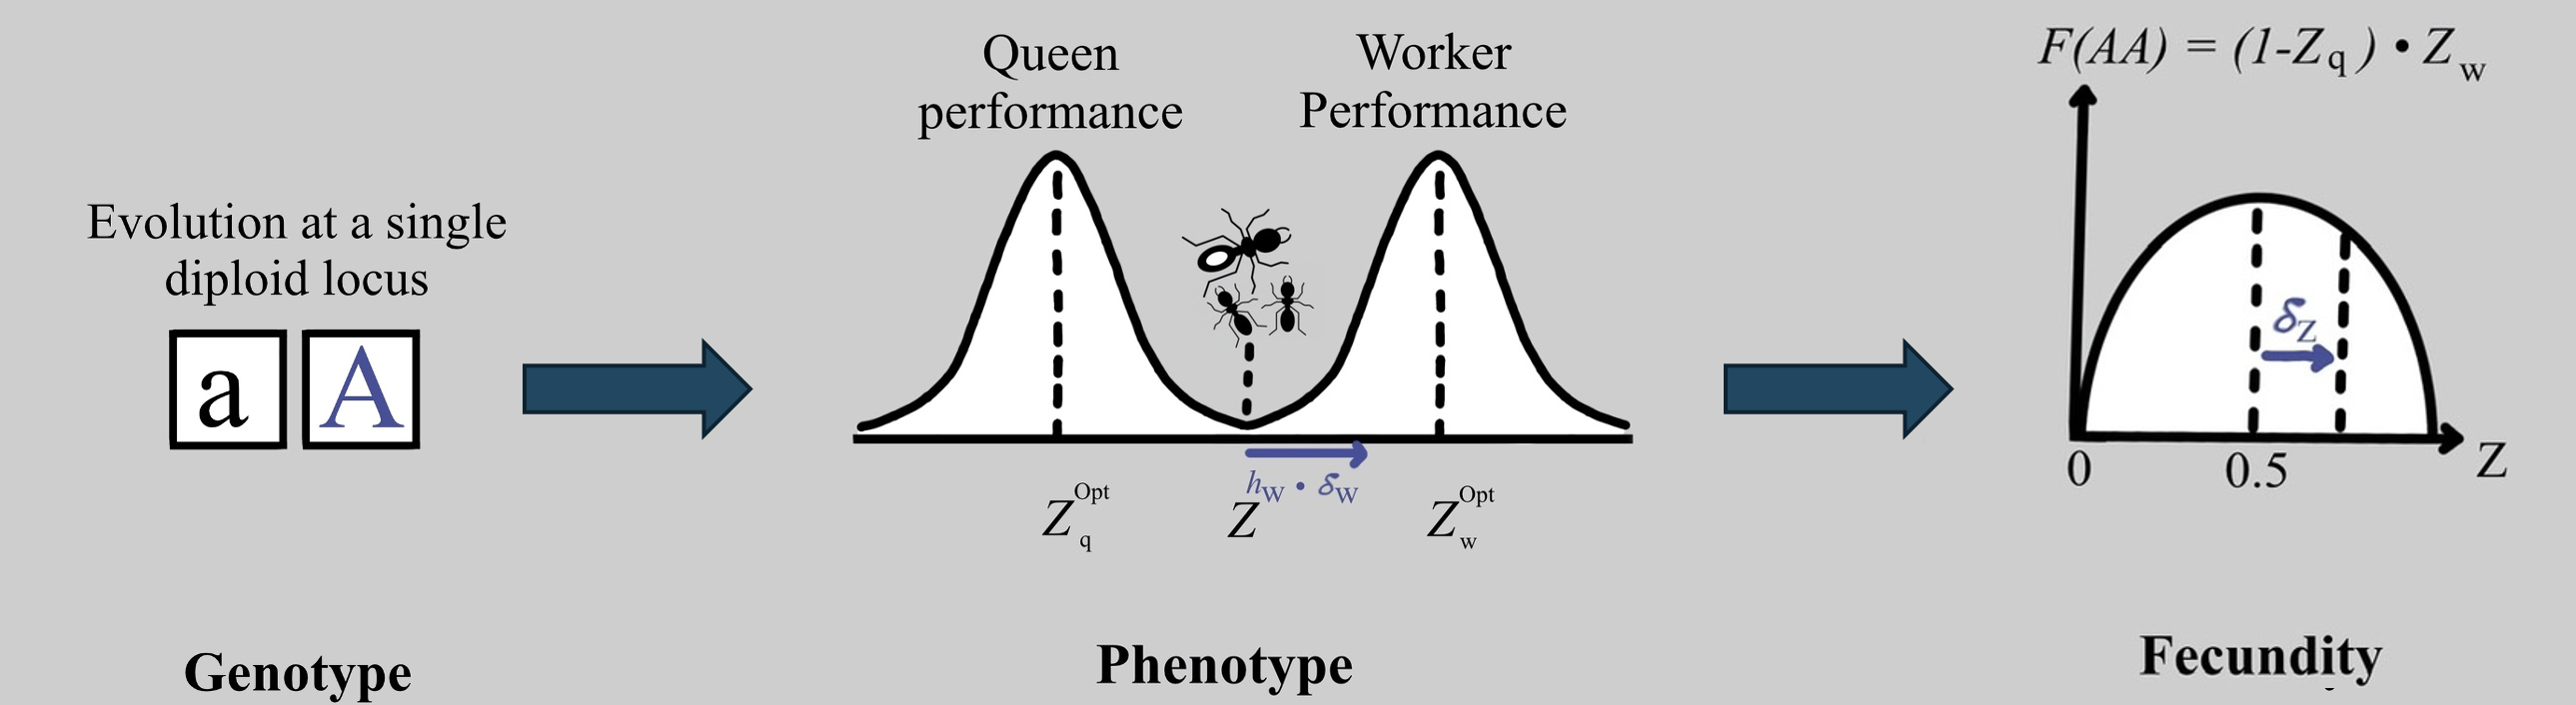
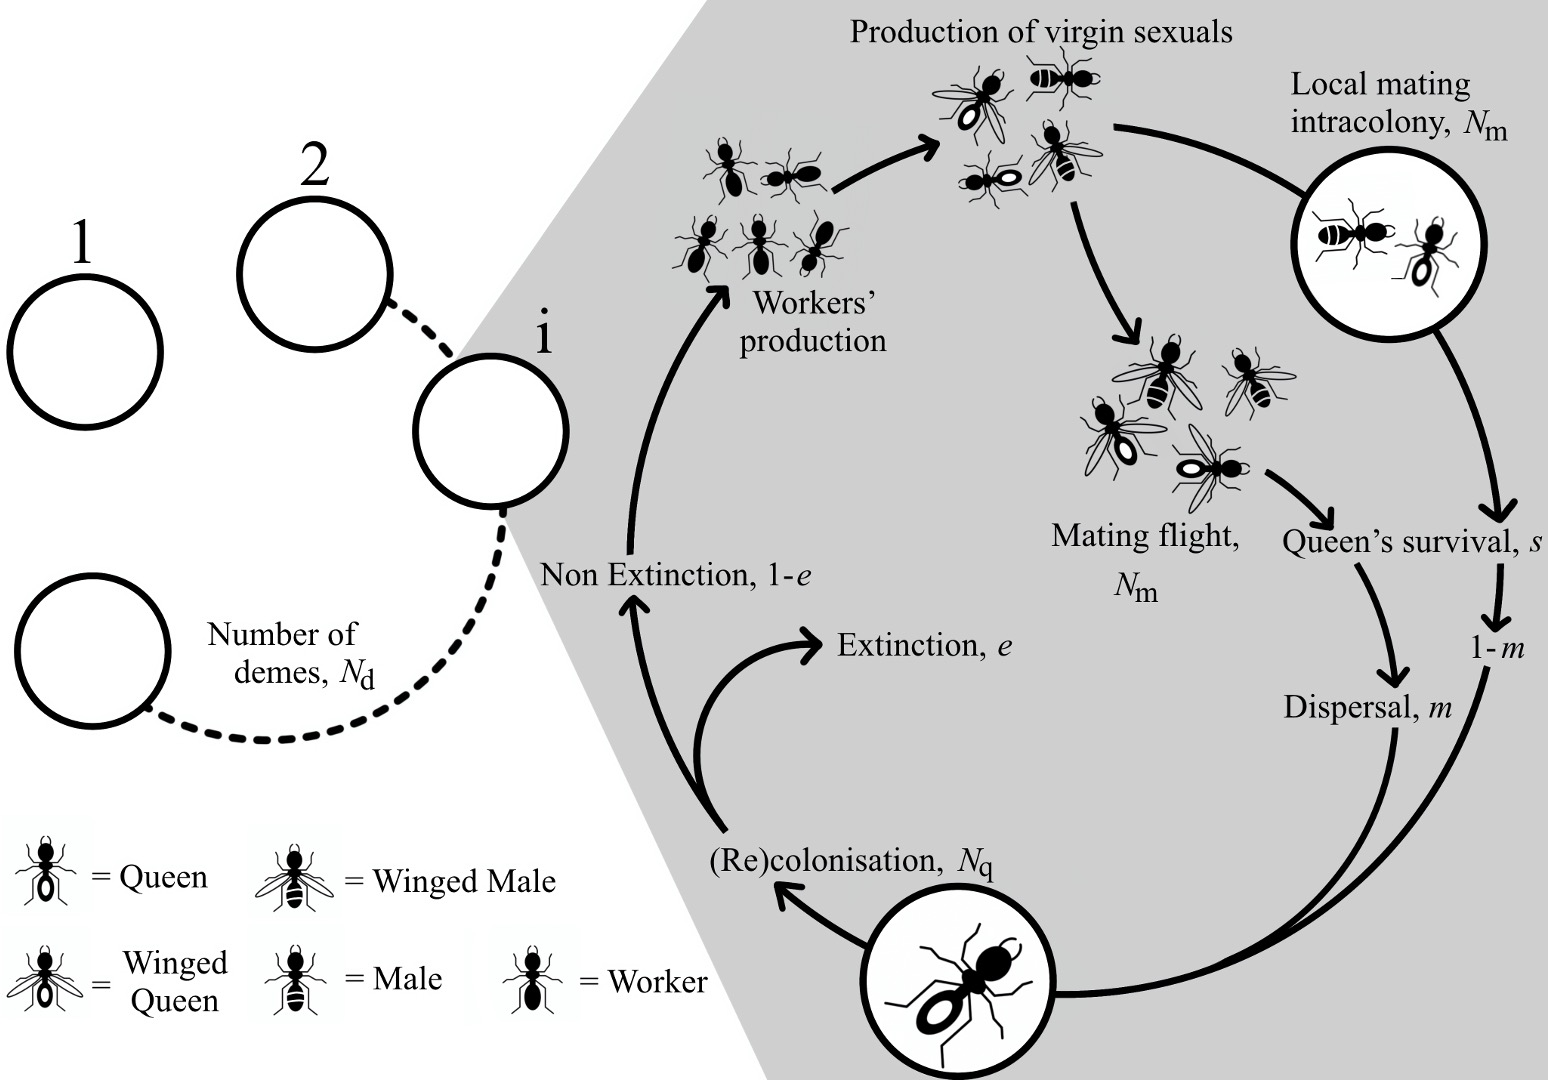

In [4]:
### --- Data Generation Using our Custom Data Generator --- ###
# error_or_not, msg = generate_dataset(n_samples=10000, reps=100, workers=4)
# print(msg)

### --- Data Loading (Adaptive for Local or Colab) --- ###
if IN_COLAB:
    print('Running in Google Colab: Fetching dataset from GitHub...')
    # Use the raw GitHub URL so Colab can download/read it directly without cloning
    csv_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/ant_ml_dataset.csv'
    df = pd.read_csv(csv_url, index_col=0)
else:
    print('Running locally: Reading dataset from local folder...')
    # Reads from your local directory where the script is saved
    df = pd.read_csv('ant_ml_dataset.csv', index_col=0)

### --- Data Cleaning --- ###
df.drop(['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'], axis=1, inplace=True) # Get rid of what is irrelevant 
                                                                                         # (not explanatory variable or response 
                                                                                         # variable).

### --- Response Variable and Features --- ###
# Here we separate features from response variables.
params_cols = ['s', 'e', 'm', 'zw', 'zq', 'dw', 'dq', 'sw', 'sq', 'Nq', 'Nm'] # Store all features together.
result_cols = ['frac_polymorphic'] # Store the response variable alone.

Running locally: Reading dataset from local folder...


/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_55317/1547868820.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'], axis=1, inplace=True) # Get rid of what is irrelevant


In [5]:
### --- Data Display --- ###
df.head(5) # Display head of the data.

,s,e,m,zw,zq,dw,dq,sw,sq,Nq,Nm,frac_polymorphic
sample_id,,,,,,,,,,,,
0,0.357718,0.230921,0.483966,0.314324,0.314324,0.806838,0.825209,0.065894,0.065894,8,2,0.00
3,0.048572,0.359939,0.239023,0.591418,0.591418,0.944899,0.173094,0.079700,0.079700,1,3,0.00
1,0.892589,0.479211,0.830789,0.885811,0.885811,0.740353,0.034923,-0.012227,-0.012227,3,7,0.00
5,0.072650,0.630431,0.530054,0.282026,0.282026,0.443350,0.346804,0.040918,0.040918,7,9,0.00
4,0.475356,0.660237,0.224082,0.257872,0.257872,0.115671,0.831151,-0.058153,-0.058153,3,9,0.26


## **Data Distribution Visualization**

Now, let's have a look at our data, so that we know **how to process it**. First, we plotted an **histogram displaying the distribution of our response variable** `frac_polymorphic` to see how our polymorphism is present in our data. For reminder, this variable represents how many cases of polymorphism are observed in percent among the replicates of one features' set. 

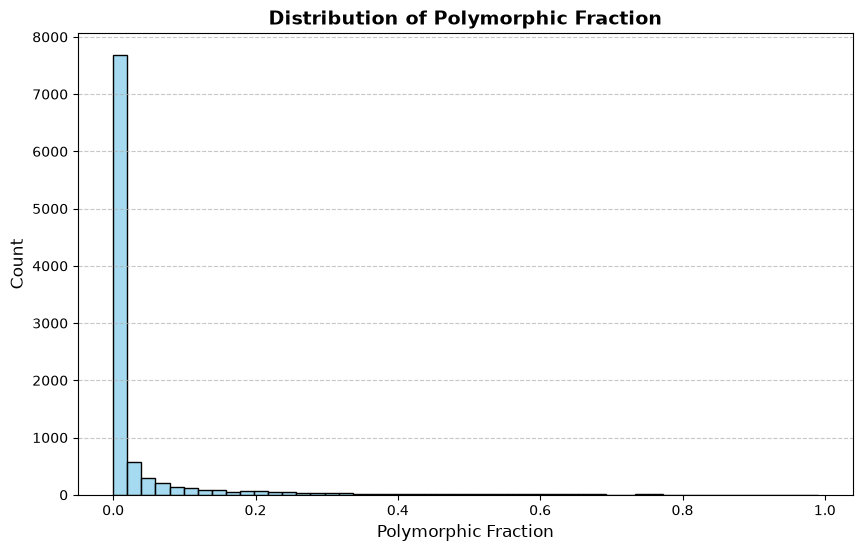

In [6]:
### --- Distribution of the Polymorphic Fraction --- ###
plt.figure(figsize=(10, 6)) # Set figure dimensions.
sns.histplot(df['frac_polymorphic'], bins=50, color='skyblue') # Plots the histogram.

# Add labels, title and a horizontal dashed lines for clarity.
plt.title('Distribution of Polymorphic Fraction', fontsize=14, fontweight='bold' )
plt.xlabel('Polymorphic Fraction', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Displays plot.
plt.show()

## **Classification or Regression Task?**
### *What the data tells us...*
As we can see, our data displays the very classical **zero inflated distribution.** With this new information in mind, we can now discuss the best course of action to perform our task. 

Intially before knowing our data distribution, we could have **framed our problem in two manners.** Either a **regression task or a classification task**, both having a solid biological sense despite answering slightly different questions. The first would allow us **to quantify how this polymorphism frequence vary**. The second loses this variation interpretation **for a simpler binary classification** that is already biologically relevant, by telling us wether we observe polymorphism or not based of a given feature set.

Since our data is so skewed, if we were doing directly a regression task our model would focus to much on all the zero values and tend to predict that we more frequently see null values than in reality. So, a **more acceptable solution** is to do a **binary classification** after a balancing of the dataset with:
- **0:** Non Polymorphic
- **1:** Polymorphic

Biologically speaking, since we mostly care about wether we observe polymorphism or not. This trade off in quantification of the frequence variance is perfectly acceptable. Nonetheless, if later we decide that quantifying it comes to be relevant, we could very easily developp a **Hurdle model**. This could be achieved by *3splitting the question in two separate consecutiv models**. First our classificator that establishes wether we see polymorphism or not. Then, we would use our regressor that is trained only on the polymorphic fraction to establish what frequency of polymorphism we expect to observe.

Now, let's see **how many cases are actually displaying some polymorphy in our randomly generated data**, since we wanna start with classification. For that we will use the `frac_polymorphic` variable and make a bar plot displaying on one side all the non null values (polymorphic) and on the other all the null values (non polymorphic).

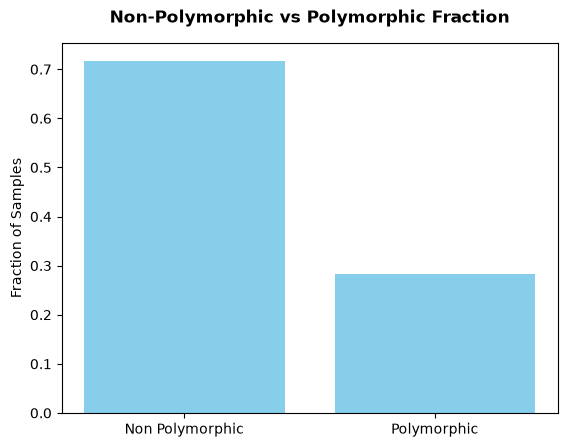

In [7]:
### --- Polymorphic Versus Non Polymorphic Barplot --- ###
barplot_polymorphic_or_not(df=df, polymorph_treshold=0.0)

<div class='alert alert-block alert-info'>
<b>Non polymorphic versus polymorphic cases discussion:</b> As we can see, it seems that there is about 2.5 times more non polymorphic than polymorphic cases. Hence, it would be good to balance our data and remove part of the non polymorphic fraction to avoid introducing some biases in our learning. Yet first, we need to observe the current distribution of our features. That will allow us to make sure that the distribution of those remains identical after we eliminated part of our data.
</div>

### **Non Polymorphic and Polymorphic Distribution Plotted for each Features**
Here is the **distribution for each features** prior to the cut that we want to operate in the data. Those shall remain identical after we dropped part of the data.

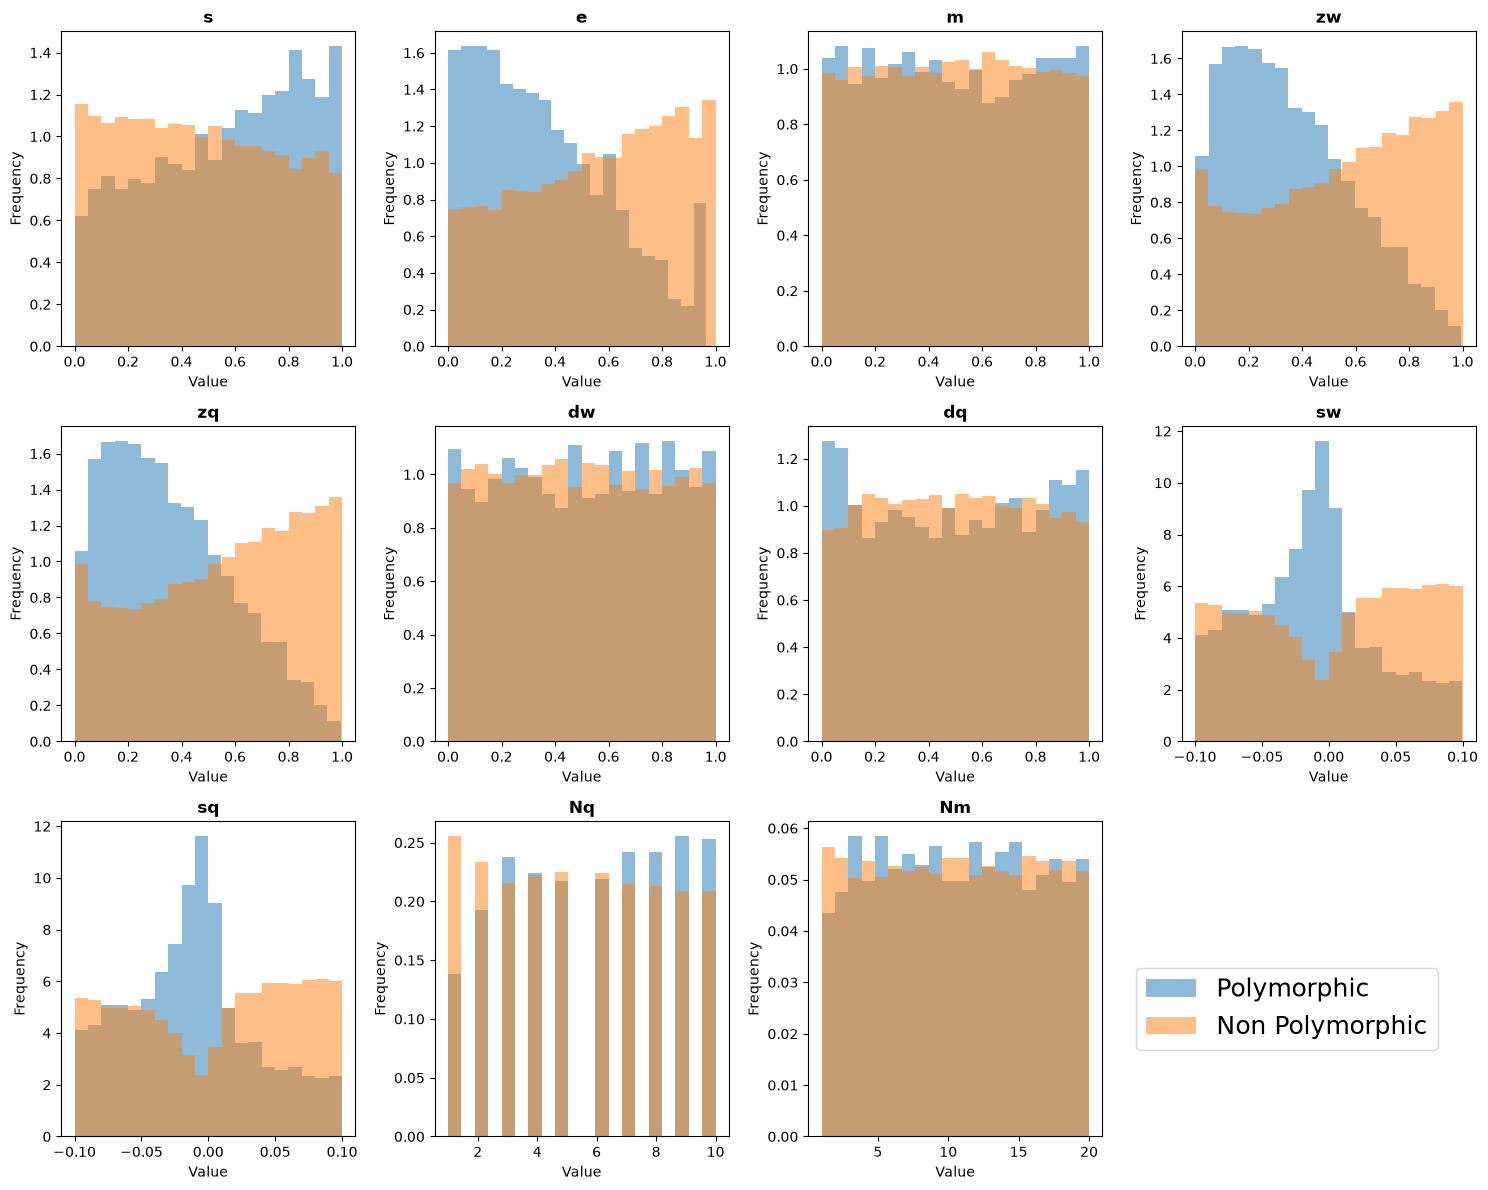

In [8]:
### --- Plotting Using the Helper plot_feature_distr --- ###
plot_feature_distr(df, params_cols)

### **Correlation Matrix of all the Features and our Response Variable**

Below we plotted the **correlation matrix of our data**. What we want to **avoid** is having **highly correlated features**. We already know that some are, by how the simulation is designed. We will wanna drop these to keep only one of them.

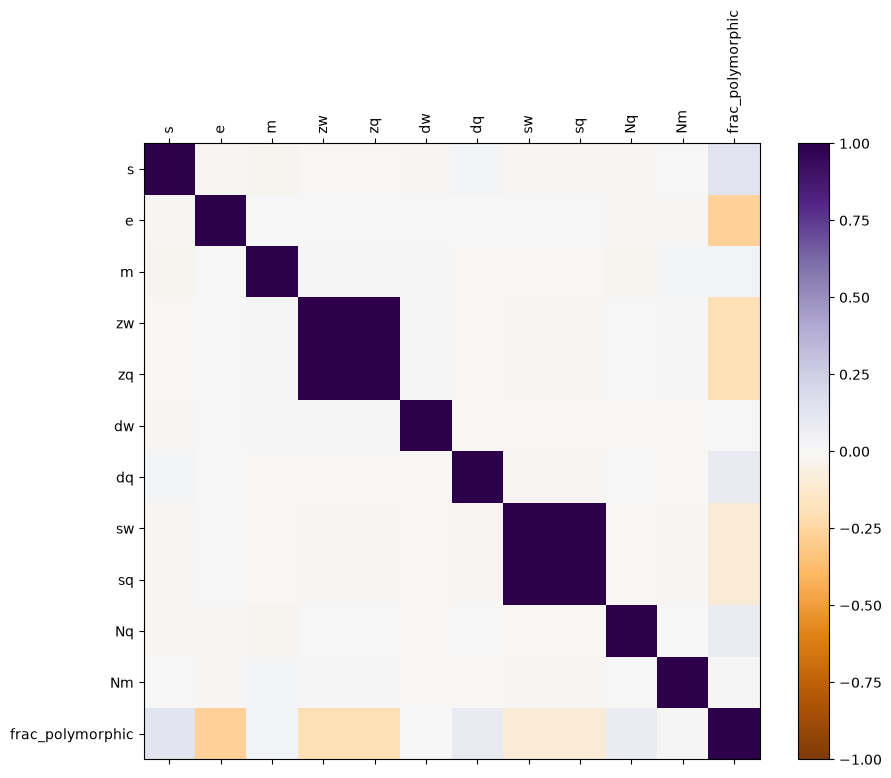

In [9]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df)

<div class='alert alert-block alert-info'>
<b>Data Distribution and Correlation:</b> As we can see, the only variable that are super correlated are Zq/Zw and Sw/Sq, which are correlated by design during the simulation. We will for each discard one of the two. As for the distribution, we need need to compare them once the cut has been operated.
</div>

## **Data Reduction**
Let's now **reduce** the **non polymorphic fraction** and **remove** our **correlated features**.

In [10]:
### --- Data Reduction --- ###
# Identify all the polymorphic cases
polymorph_treshold = 0.0
polymorph_samples = (df['frac_polymorphic'] > polymorph_treshold)
df_non_poly_thin = df[~polymorph_samples].sample(n=polymorph_samples.sum().item())
df_thin = pd.concat([df[polymorph_samples], df_non_poly_thin]) # Dropping part of 
                                                               # the non polymorphic.
# Remove the highly correlated features.                                                       
df_thin.drop(['zw', 'sw'], axis=1, inplace=True) # Removing correlated features.
params_cols.remove('zw')
params_cols.remove('sw')

/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_55317/3475727306.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_thin.drop(['zw', 'sw'], axis=1, inplace=True) # Removing correlated features.


### **After Data Reduction**

In the code below, we check that our data is **still respecting its previous distribution for each features**, now that we equalized it. As we can see with `df_thin.describe().head(3)`, we have **5620 samples** once we operated our reduction.

In [11]:
### --- Displaying the Statistics of the New Data Frame --- ###
df_thin.describe().head(3)

,s,e,m,zq,dw,dq,sq,Nq,Nm,frac_polymorphic
count,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000,5620.000000
mean,0.519580,0.460184,0.498017,0.457766,0.498778,0.498021,-0.004112,5.609075,10.564769,0.062496
std,0.287873,0.285259,0.288768,0.278972,0.289393,0.292099,0.054977,2.857664,5.764054,0.136305


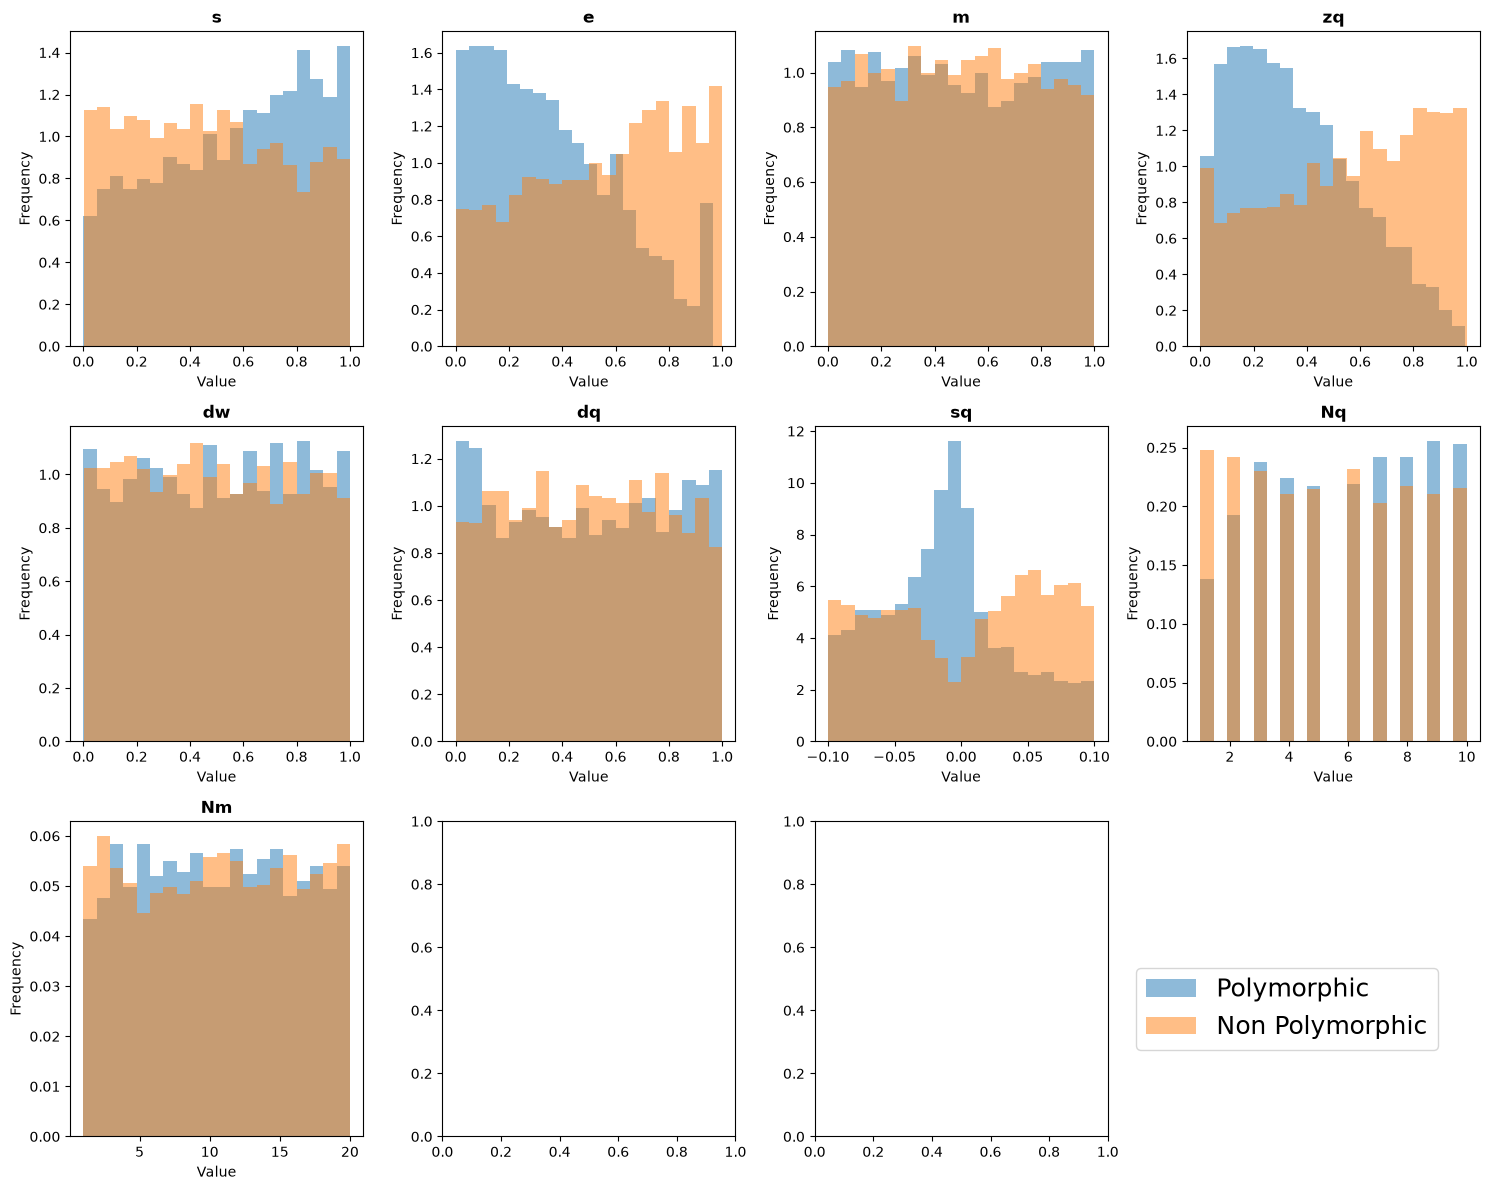

In [12]:
### --- Plotting Using the Helper plot_feature_distr  --- ###
plot_feature_distr(df_thin, params_cols)

<div class='alert alert-block alert-info'>
<b>Data Distribution:</b> Perfect, our distribution remain nearly perfectly identical. The two white boxes correspond to our two variables that we dropped.
</div>

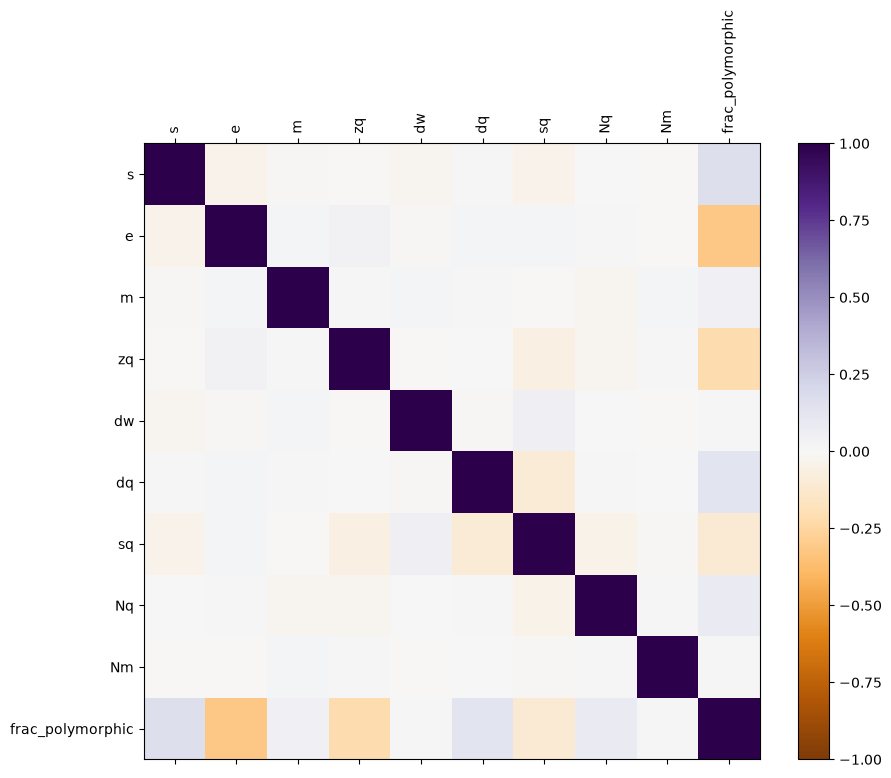

In [13]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df_thin)

<div class='alert alert-block alert-info'>
<b>Data Correlation:</b> Perfect, our data is no longer having highly correlated features.
</div>

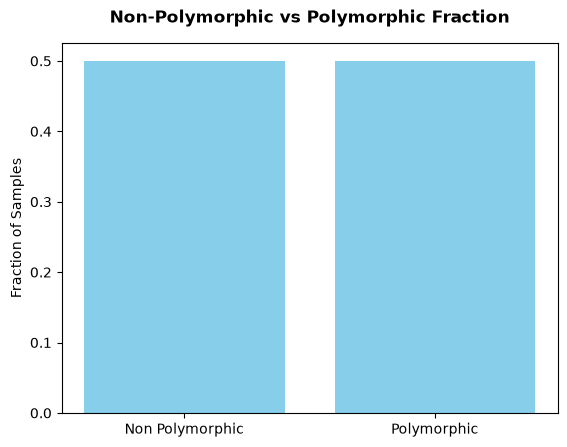

In [14]:
### --- Polymorphic Versus Non Polymorphic Barplot --- ###
barplot_polymorphic_or_not(df=df_thin, polymorph_treshold=0.0)

<div class='alert alert-block alert-info'>
<b>Barplot verification:</b> As we can see, with the barplot: our data is now balanced.
</div>

## **Data Response Variable Correction**

Now, that we are sure that we **reduced our data correctly**, there is one last step to take it is simply to **change our `frac_polymorphic`** continuous variable into a binary variable called **`polymorphic`** for our classification task with:
- **0:** Non polymorphic
- **1:** Polymorphic

In [15]:
### --- Changing our Response Variable for Classification --- ###
# Addding our new column `Polymorphic` to our data frame.
df_thin['polymorphic'] = (df_thin['frac_polymorphic'] > 0).astype(int)
df_thin.drop(['frac_polymorphic'], axis=1, inplace=True) # Removing our old variable.
result_cols = ['polymorphic'] # correcting our explanatory variable list.

# Displays our new equillibrate and ready to be preprocessed data.
df_thin.head(5)

/var/folders/h6/9k3xyll50pld7y_xhy85yjzm0000gn/T/ipykernel_55317/773285483.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_thin.drop(['frac_polymorphic'], axis=1, inplace=True) # Removing our old variable.


,s,e,m,zq,dw,dq,sq,Nq,Nm,polymorphic
sample_id,,,,,,,,,,
4,0.475356,0.660237,0.224082,0.257872,0.115671,0.831151,-0.058153,3,9,1
6,0.950576,0.340998,0.824687,0.061601,0.879456,0.219170,0.038176,8,2,1
7,0.365080,0.745140,0.400069,0.189242,0.495235,0.494838,-0.042692,7,5,1
8,0.470395,0.663667,0.124523,0.064909,0.544222,0.424700,0.047439,4,18,1
19,0.968545,0.105871,0.410403,0.127432,0.333015,0.392471,0.060766,6,10,1


## **Split the Data**

We are splitting our data set of 5620 samples in the following manner:
- **Train set:** 90%
- **Validation Set:** 0% (Because, we will do some cross validation)
- **Test set:** 10%

In [ ]:
### --- Variable and Features Separation for Handling --- ###
X = df_thin[params_cols]
y = df_thin[result_cols]

### --- Splitting the Data between Train, Validation and Test Sets --- ###
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1)

## **Preprocessing the Data**

Here are all the features used in the ants life cycle simulation:

1. **Nq:** *number of queens per deems, ranges from 1 to 10 **&#8594;** requires a transformation: **encoding in categorical variable.***
2. **Nm:** *number of reproductive males, ranges from 1 to 20 **&#8594;** requires a transformation: **encoding in categorical variable.***
3. **s:** *survival rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
4. **e:** *extinction rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
5. **m:** *migration rate, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
6. **dq:** *dominance in the queens, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
7. **dw:** *dominance in the workers, each ranges from 0.0 to 1.0 **&#8594;** requires no transformation.*
8. **zq(=zw):** *current level fitness of the classes, ranges from 0 (workers' optimum) to 1 (queens' optimum) **&#8594;** requires no transformation.*
9. **sq(=sw):** *mutation effect, ranges from -0.1 (workers' favorable) to +0.1 (queens' favorable) **&#8594;** requires a transformation: **scaling from 0 to 1.***


In [17]:
### --- Data Preprocessing --- ###
scale_cols = ['sq'] # Column to scale.
cat_cols = ['Nq', 'Nm'] # Column that are categorical.

# Transformer Creation
ct = ColumnTransformer(
    [('one_hot', OneHotEncoder(), cat_cols),
     ('scaled', MinMaxScaler(feature_range=(0, 1)), scale_cols)],
    remainder='passthrough')

# Data Transformation
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

<div class='alert alert-block alert-info'>
<b>Data Preprocessing:</b> Now, our data is ready to be used for our machine learning!!
</div>

## **Logistic regression**
Now that our data is ready for our classification task. Let's start simple and do a **logistic regression** to start with. Below, we tried to **tune the hyperparameter C** (reducing regularization), which is the only tunable hyperparameter. We have 73 % accuracy on the test set not too bad! Seems like there is not much more than we can do except visualize how well our model performs in a more detailed manner.

In [67]:
### --- Hyperparameter Tuning (Regularization C) on Validation Set --- ###
C_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
# C is the inverse of regularization strength (smaller values = stronger regularization)
best_C = None              # To store the best C value.
best_val_accuracy = 0.0    # To store the best model accuracy on the validation set.
best_model_log_regression = None          # To store the best model.

# 1. Define the parameter grid.
param_grid = {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

# 2. Initialize the base model.
log_reg_model = LogisticRegression(random_state=1, max_iter=1000)

# 3. Setup GridSearchCV.
grid_search = GridSearchCV(
    estimator=log_reg_model, 
    param_grid=param_grid, 
    cv=5,                       # cv=10 means 10-fold cross-validation on your training data.
    scoring='accuracy',         # scoring='accuracy' optimizes for accuracy.
    n_jobs=-1
)

# 4. Fit the grid search
search = grid_search.fit(X_train, y_train)
best_C = grid_search.best_params_['C']
best_model_log_regression = grid_search.best_estimator_

### --- Accuracies on Train, Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_model_log_regression.predict(X_train))
CVval_acc   = search.best_score_
test_acc  = accuracy_score(y_test, best_model_log_regression.predict(X_test))

print(f'--- Set Accuracies for Best C: {best_C} ---')
print(f'Train Accuracy:            {train_acc:.4f}')
print(f'Cross-Validation Accuracy: {CVval_acc:.4f}')
print(f'Test Accuracy:             {test_acc:.4f}\n')

--- Set Accuracies for Best C: 0.01 ---
Train Accuracy:            0.7404
Cross-Validation Accuracy: 0.7378
Test Accuracy:             0.7260



/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-ve

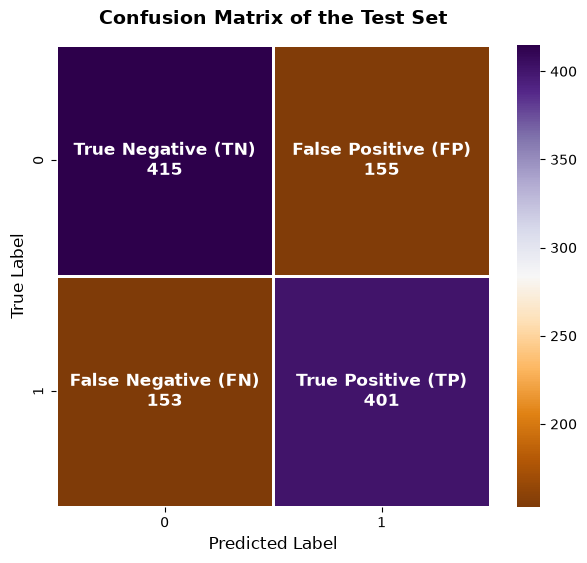

In [20]:
### --- Confusion Matrix for Logistic Regression --- ###
plot_confusion_matrix(model=best_model_log_regression, X_set=X_test, y_set=y_test, type_of_set="Test")

Well as we have discussed before, we can see that we are right **three times out of four** with our **logistic regression**, whereas if we were going by luck we would be wrong one time out two... Yet, there is much that we can improve. Let's see the ROC now! It shows the trade off between recall and precision. 

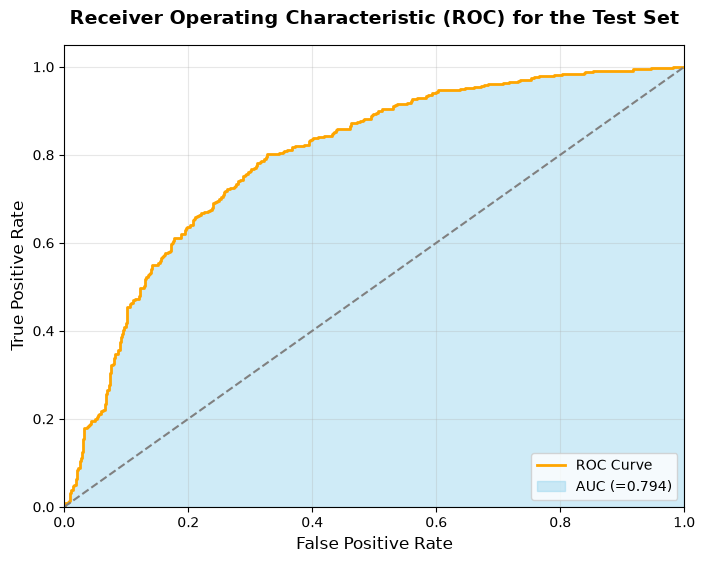

In [21]:
### --- ROC Curve --- ###
plot_roc(model=best_model_log_regression, X_set=X_test, y_set=y_test, type_of_set="Test")

## **Decision Tree**

In [22]:
### --- Simple Decision Tree --- ##
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train['polymorphic'])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [23]:
### --- Accuracies on Train, Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, dt_model.predict(X_train))
test_acc  = accuracy_score(y_test, dt_model.predict(X_test))

print('------ Set Accuracies ------')
print(f'Train Accuracy:      {train_acc:.4f}')
print(f'Test Accuracy:       {test_acc:.4f}\n')

------ Set Accuracies ------
Train Accuracy:      1.0000
Test Accuracy:       0.8078



In [65]:
### --- Best Decision Tree --- ###

# Here is the hyperparameter space we found 
# was the best to reduce overfitting.
hyp_params = dict(
    max_depth = range(1, 7),
    min_samples_leaf = range(5, 10),
    max_features=[None, 'sqrt', 'log2'],
    criterion = ['gini', 'entropy']
)

# Let's randomly search the hyperparameter space
dt_opt = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=0, ccp_alpha =0.008), 
    hyp_params, 
    random_state=0, 
    cv=10, 
    scoring='accuracy'
)

print("------ Running Randomized Search for Decision Tree ------")
search = dt_opt.fit(X_train, y_train['polymorphic'])

# 2. Fix the variable name from 'grid_search' to 'search'
best_model_dt = search.best_estimator_
best_dt_params = search.best_params_

print(f"\nBest Hyperparameters Found: {best_dt_params}\n")

### --- Accuracies on Train, Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_model_dt.predict(X_train))
CVval_acc   = search.best_score_
test_acc  = accuracy_score(y_test, best_model_dt.predict(X_test))

print('------ Set Accuracies ------')
print(f'Train Accuracy:      {train_acc:.4f}')
print(f'Cross-validation Accuracy: {CVval_acc:.4f}')
print(f'Test Accuracy:       {test_acc:.4f}\n')

------ Running Randomized Search for Decision Tree ------

Best Hyperparameters Found: {'min_samples_leaf': 6, 'max_features': None, 'max_depth': 5, 'criterion': 'entropy'}

------ Set Accuracies ------
Train Accuracy:      0.7967
Cross-validation Accuracy: 0.7689
Test Accuracy:       0.7945



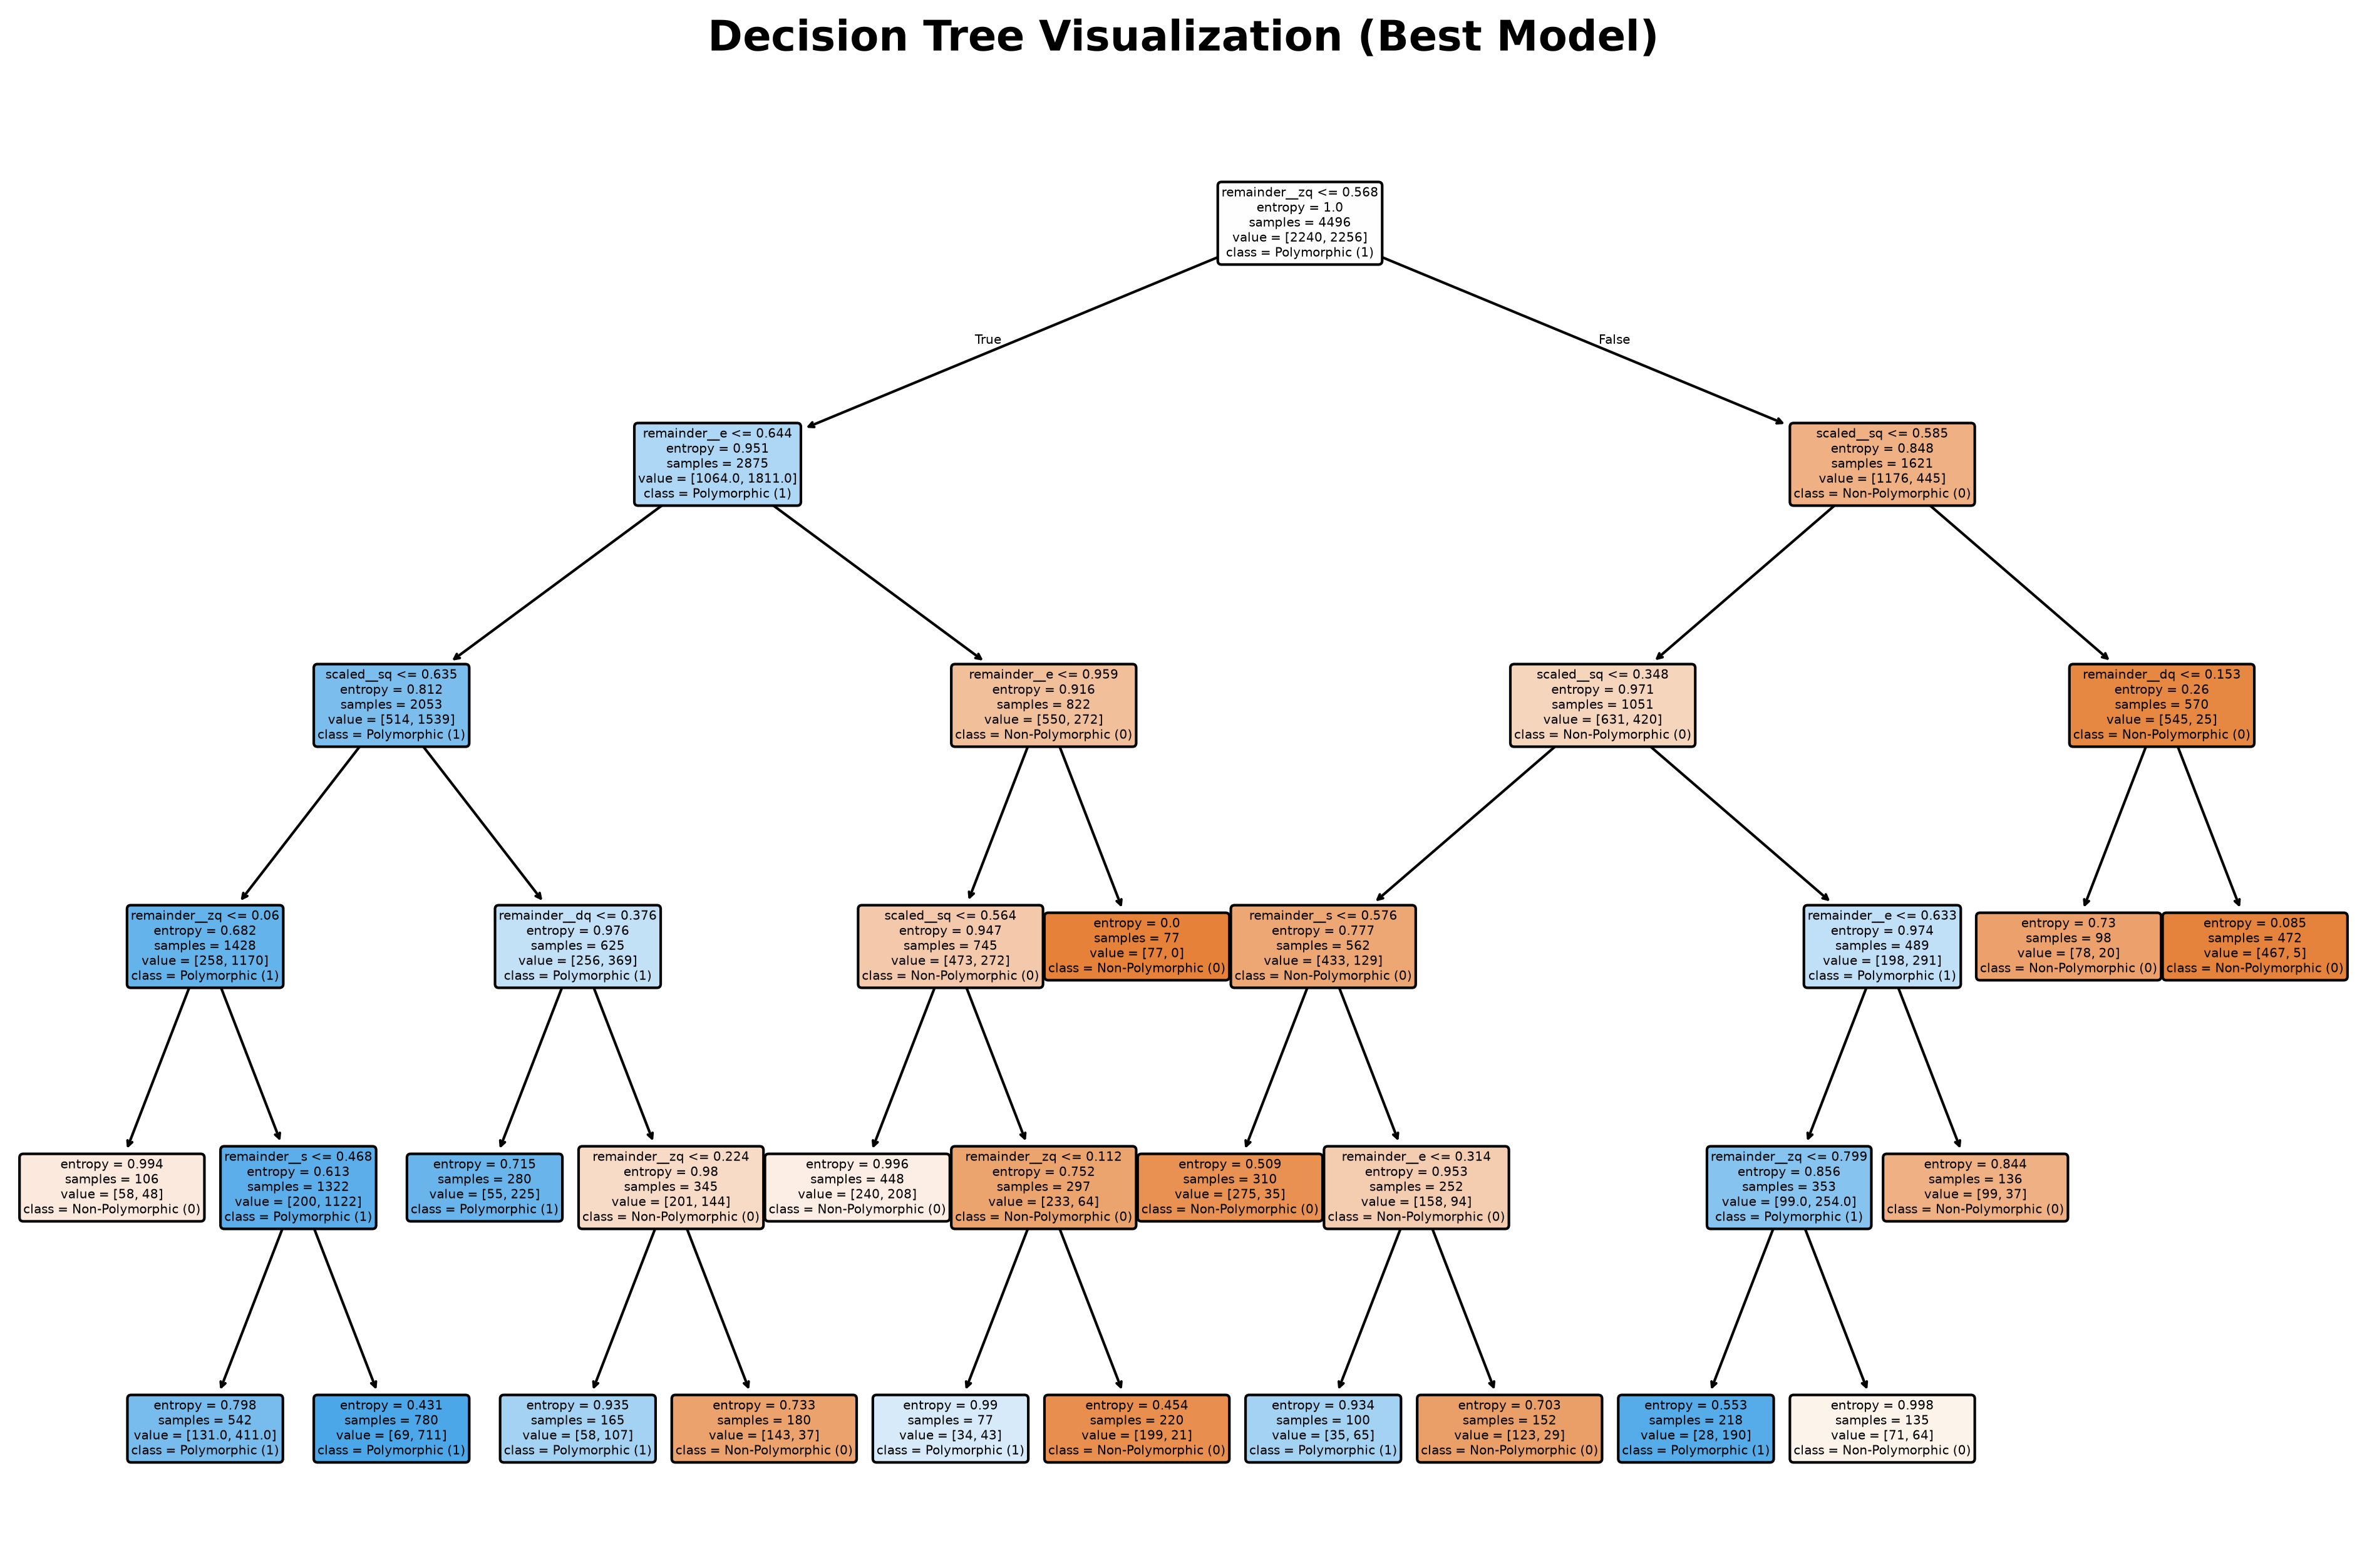

In [66]:
# Get the feature names after the ColumnTransformer transformation
encoded_feature_names = ct.get_feature_names_out()

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10), dpi=300) # High DPI makes large trees crisper to zoom in on

plot_tree(
    best_model_dt, 
    feature_names=encoded_feature_names, 
    class_names=['Non-Polymorphic (0)', 'Polymorphic (1)'],
    filled=True,          # Colors nodes by majority class
    rounded=True,         # Rounds the node boxes for a clean look
)

plt.title("Decision Tree Visualization (Best Model)", fontsize=16, fontweight='bold', pad=20)
plt.show()

## **Random Forest**

In [27]:
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train['polymorphic'])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [28]:
### --- Accuracies on Train, Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, rf_model.predict(X_train))
test_acc  = accuracy_score(y_test, rf_model.predict(X_test))

print('------ Set Accuracies ------')
print(f'Train Accuracy:      {train_acc:.4f}')
print(f'Test Accuracy:       {test_acc:.4f}\n')

------ Set Accuracies ------
Train Accuracy:      1.0000
Test Accuracy:       0.8568



In [29]:
# Define a hyperparameter space that restricts tree complexity
param_dist = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': range(1,8),                   # Limiting depth stops memorization
    'min_samples_split': [3, 5, 10, 20, 50],       # Requires more samples to split a node
    'min_samples_leaf': [2, 5, 10, 20],         # Prevents leaves from having tiny, hyper-specific groups
    'max_features': ['sqrt', 'log2', 0.5],      # Subsets features per tree to add diversity
    'bootstrap': [True]
}

rf_base = RandomForestClassifier(random_state=1)

rf_opt = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=15,          # Number of random combinations to try
    cv=5,               # 5-fold cross-validation on the training set
    scoring='accuracy',
    random_state=1,
    n_jobs=-1           # Uses all available CPU cores
)

print("------ Running Randomized Search for Random Forest ------")
search = rf_opt.fit(X_train, y_train['polymorphic'])

best_rf_model = search.best_estimator_
best_rf_params = search.best_params_

print(f"\nBest Hyperparameters Found: {best_rf_params}\n")

### --- Accuracies on Train, Validation, and Test Sets --- ###
train_acc = accuracy_score(y_train, best_rf_model.predict(X_train))
CVval_acc   = search.best_score_
test_acc  = accuracy_score(y_test, best_rf_model.predict(X_test))

print('------ Set Accuracies ------')
print(f'Train Accuracy:      {train_acc:.4f}')
print(f'Cross-validation Accuracy: {CVval_acc:.4f}')
print(f'Test Accuracy:       {test_acc:.4f}\n')

------ Running Randomized Search for Random Forest ------

Best Hyperparameters Found: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 7, 'bootstrap': True}

------ Set Accuracies ------
Train Accuracy:      0.9164
Cross-validation Accuracy: 0.8590
Test Accuracy:       0.8496



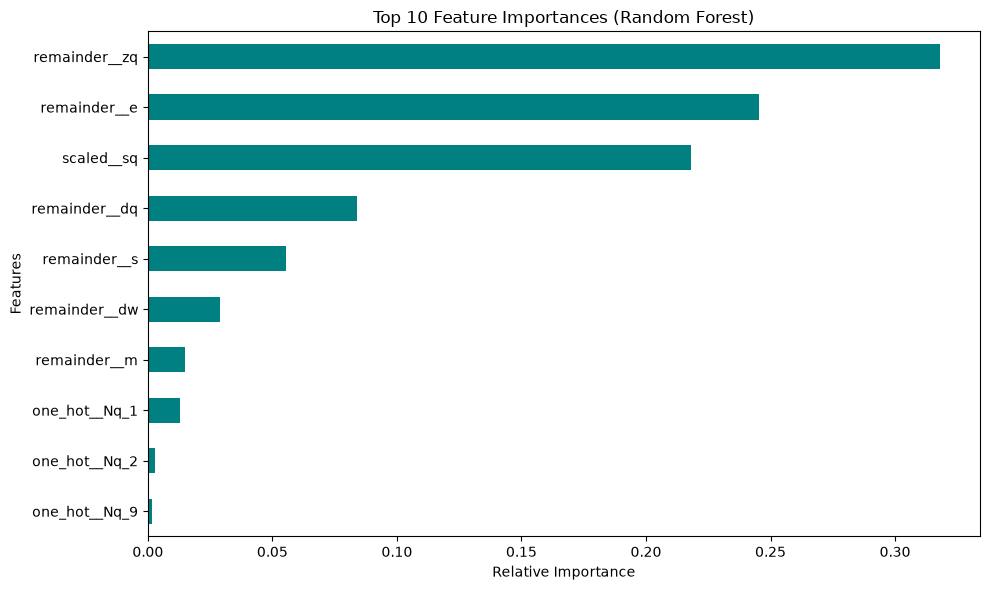

In [30]:
# 1. Extract feature names from your preprocessor 
# (Replace `preprocessor` with whatever you named your ColumnTransformer or Pipeline step)
feature_names = ct.get_feature_names_out()

# 2. Build the Series using the correct feature names
importances = pd.Series(best_rf_model.feature_importances_, index=feature_names)

# 3. Plot the top 10 features
plt.figure(figsize=(10, 6))
importances.nlargest(10).sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

Xg boost

In [31]:
# 1. Define the hyperparameter search space for XGBoost
param_dist_xgb = {
    'n_estimators': [300, 500, 1000],
    'max_depth': range(1,3),                 # Depth of sequential trees
    'learning_rate': [0.01, 0.03],     # Step size shrinkage to prevent overfitting
    'subsample': [0.5, 0.6, 0.7],               # Fraction of samples used per tree
    'colsample_bytree': [0.5, 0.6, 0.7],        # Fraction of features used per tree
    'min_child_weight': [9, 10],              # Minimum sum of instance weight needed in a child
    'reg_alpha': [1, 5],                 # L1 regularization (encourages sparsity)
    'reg_lambda': [1, 5]                # L2 regularization (smooths weights)
}

# 2. Initialize base XGBoost classifier
xgb_base = XGBClassifier(random_state=1, eval_metric='logloss')

# 3. Setup Randomized Search
xgb_opt = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist_xgb,
    n_iter=15,          # Number of parameter combinations to try
    cv=5,               # 5-fold cross-validation
    scoring='accuracy',
    random_state=1,
    n_jobs=-1           # Use all CPU cores
)

print("------ Running Randomized Search for XGBoost ------")
search_xgb = xgb_opt.fit(X_train, y_train['polymorphic'])

best_xgb_model = search_xgb.best_estimator_
best_xgb_params = search_xgb.best_params_
CVval_acc = search.best_score_

print(f"\nBest Hyperparameters Found: {best_xgb_params}\n")

# 4. Evaluate Accuracies across sets
train_acc = accuracy_score(y_train['polymorphic'], best_xgb_model.predict(X_train))
test_acc  = accuracy_score(y_test['polymorphic'], best_xgb_model.predict(X_test))

print('------ Tuned XGBoost Set Accuracies ------')
print(f'Train Accuracy:            {train_acc:.4f}')
print(f'Cross validation Accuracy: {CVval_acc:.4f}')
print(f'Test Accuracy:             {test_acc:.4f}\n')


------ Running Randomized Search for XGBoost ------

Best Hyperparameters Found: {'subsample': 0.5, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 9, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.7}

------ Tuned XGBoost Set Accuracies ------
Train Accuracy:            0.8608
Cross validation Accuracy: 0.8590
Test Accuracy:             0.8221



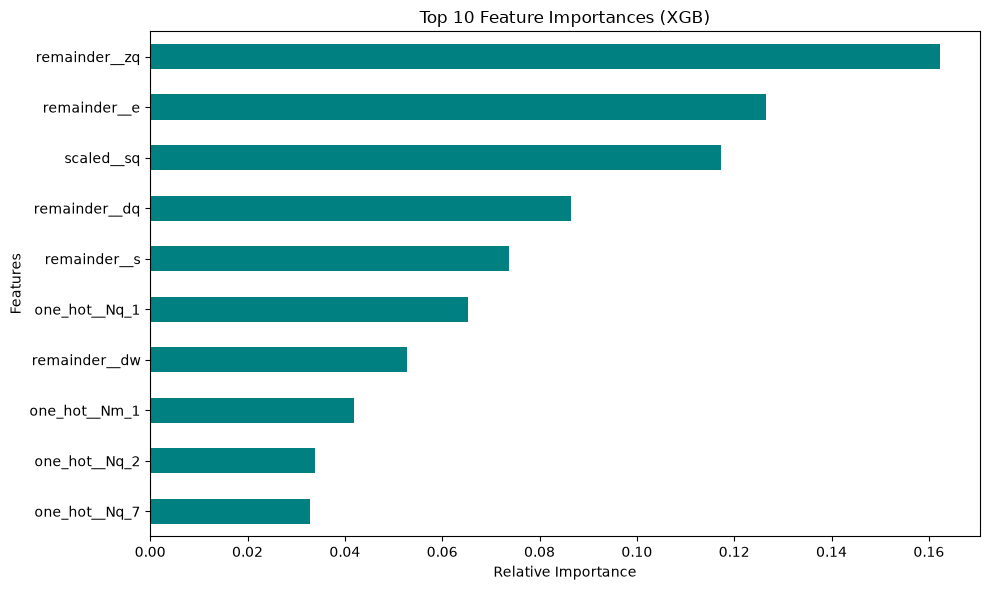

In [32]:
# 1. Extract feature names from your preprocessor 
# (Replace `preprocessor` with whatever you named your ColumnTransformer or Pipeline step)
feature_names = ct.get_feature_names_out()

# 2. Build the Series using the correct feature names
importances = pd.Series(best_xgb_model.feature_importances_, index=feature_names)

# 3. Plot the top 10 features
plt.figure(figsize=(10, 6))
importances.nlargest(10).sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances (XGB)')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

MLP

In [33]:
# 1. Define the hyperparameter search space for the MLP
param_dist_mlp = {
    'hidden_layer_sizes': [(50,), (100,), (50, 25), (100, 50)], # Network architecture
    'activation': ['relu', 'tanh'],                              # Activation functions
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1.0],                    # L2 regularization strength (prevents overfitting)
    'learning_rate_init': [0.001, 0.01, 0.05],                   # Initial learning rate
    'max_iter': [300, 500]                                       # Max training epochs
}

# 2. Initialize base MLP classifier (early_stopping=True helps prevent overfitting automatically)
mlp_base = MLPClassifier(random_state=1, early_stopping=True)

# 3. Setup Randomized Search
mlp_opt = RandomizedSearchCV(
    estimator=mlp_base,
    param_distributions=param_dist_mlp,
    n_iter=10,          # Number of parameter combinations to try
    cv=5,               # 5-fold cross-validation
    scoring='accuracy',
    random_state=1,
    n_jobs=-1           # Use all CPU cores
)

print("------ Running Randomized Search for MLP ------")
search_mlp = mlp_opt.fit(X_train, y_train['polymorphic'])

best_mlp_model = search_mlp.best_estimator_
best_mlp_params = search_mlp.best_params_
CVval_acc = search.best_score_

print(f"\nBest Hyperparameters Found: {best_mlp_params}\n")

# 4. Evaluate Accuracies across sets
train_acc = accuracy_score(y_train['polymorphic'], best_mlp_model.predict(X_train))
test_acc  = accuracy_score(y_test['polymorphic'], best_mlp_model.predict(X_test))

print('------ Tuned MLP Set Accuracies ------')
print(f'Train Accuracy:      {train_acc:.4f}')
print(f'Validation Accuracy: {CVval_acc:.4f}')
print(f'Test Accuracy:       {test_acc:.4f}\n')

------ Running Randomized Search for MLP ------

Best Hyperparameters Found: {'max_iter': 300, 'learning_rate_init': 0.05, 'hidden_layer_sizes': (100, 50), 'alpha': 0.1, 'activation': 'tanh'}

------ Tuned MLP Set Accuracies ------
Train Accuracy:      0.8806
Validation Accuracy: 0.8590
Test Accuracy:       0.8630



/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycl

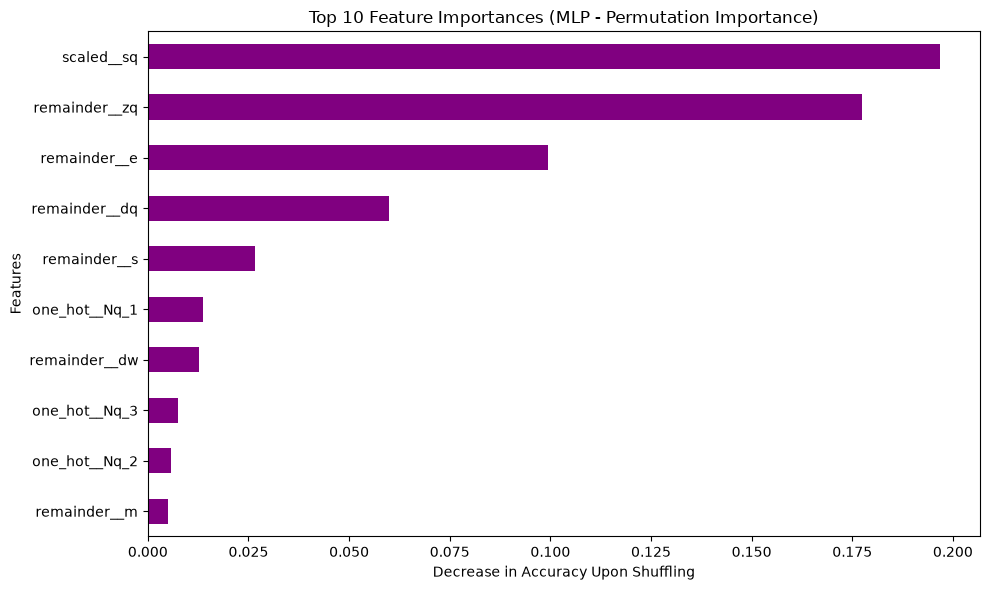

In [34]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# 1. Quickly create X_test_df from your existing X_test and ColumnTransformer (ct)
feature_names = ct.get_feature_names_out()
if hasattr(X_test, "toarray"):
    X_test_df = pd.DataFrame(X_test.toarray(), columns=feature_names)
else:
    X_test_df = pd.DataFrame(X_test, columns=feature_names)

# 2. Calculate permutation importance on the test set
result = permutation_importance(
    best_mlp_model, 
    X_test_df, 
    y_test['polymorphic'], 
    n_repeats=10, 
    random_state=1, 
    n_jobs=-1
)

# 3. Put the results into a pandas Series and plot
perm_importances = pd.Series(result.importances_mean, index=feature_names)

plt.figure(figsize=(10, 6))
perm_importances.nlargest(10).sort_values().plot(kind='barh', color='purple')
plt.title('Top 10 Feature Importances (MLP - Permutation Importance)')
plt.xlabel('Decrease in Accuracy Upon Shuffling')
plt.ylabel('Features')
plt.tight_layout()
plt.show()